PART 2: QUESTION A

    - Main Dataset folder: SUIT_Payload_Part2

Methodology Undertaken: 

    - Payload used: Solar Ultraviolet Imaging Telescope (SUIT)
    - File type: FITS
    - Period of File Extraction: 18 April 2025 to 22 April 2025
    - Filter considered: NB03 (Wavelength: 279.6 nm)
    - Region of Sun: Chromosphere

In [2]:
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.visualization import ImageNormalize, SqrtStretch

import sunpy.map
from skimage import measure
from skimage.filters import threshold_otsu

from sunpy.map import Map

In [3]:
# FITS files are located in folder named "SUIT_Payload_Part2"
filepath = os.path.join("./SUIT_Payload_Part2/", "*.fits")
fits_files_sorted = sorted(glob.glob(filepath))

# Recording the observation time of each file 
time_frame = []
for file in fits_files_sorted:
    with fits.open(file) as hdul:
        header = hdul[0].header
        time_frame.append(header.get("DATE-OBS", os.path.basename(file)))

datetime_array = pd.to_datetime(time_frame)

print(f"Found {len(fits_files_sorted)} files:")
for f, t in zip(fits_files_sorted, datetime_array):
    print(f"  {os.path.basename(f):40s}  {t}")

Found 7 files:
  SUT_T25_0588_000860_Lev1.0_2025-04-15T21.50.19.930_0973NB03.fits  2025-04-15 21:50:19.930945
  SUT_T25_0588_000863_Lev1.0_2025-04-16T18.13.04.497_0973NB03.fits  2025-04-16 18:13:04.497550
  SUT_T25_0589_000866_Lev1.0_2025-04-18T21.12.32.506_0973NB03.fits  2025-04-18 21:12:32.506255
  SUT_T25_0589_000869_Lev1.0_2025-04-19T19.38.53.133_0973NB03.fits  2025-04-19 19:38:53.133955
  SUT_T25_0589_000872_Lev1.0_2025-04-20T22.11.02.419_0973NB03.fits  2025-04-20 22:11:02.419330
  SUT_T25_0589_000875_Lev1.0_2025-04-21T18.24.26.898_0973NB03.fits  2025-04-21 18:24:26.898155
  SUT_T25_0589_000878_Lev1.0_2025-04-22T20.16.50.204_0973NB03.fits  2025-04-22 20:16:50.204970


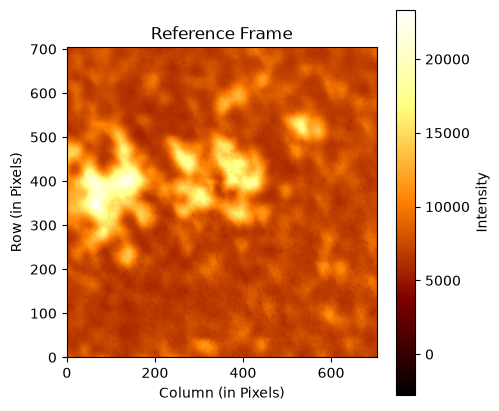

In [4]:
# Choosing an initial reference frame to get Active Regions
ref_frame = Map(fits_files_sorted[4])
ref_frame_data = ref_frame.data

plt.figure(figsize=(5,5))
plt.title("Reference Frame")
plt.imshow(ref_frame_data, cmap="afmhot", origin="lower")       # cmap = "afmhot" to understand intensities visually
plt.xlabel("Column (in Pixels)")
plt.ylabel("Row (in Pixels)")
plt.colorbar(label="Intensity")

plt.show()

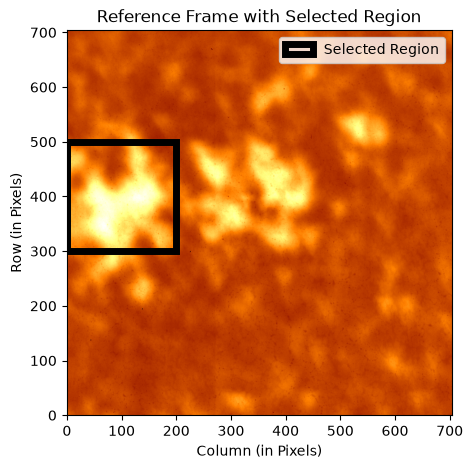

In [5]:
# Creation of the boundary box w.r.t reference frame to study AR contours

ROW_MIN, ROW_MAX = 300, 500
COL_MIN, COL_MAX = 0, 200

fig, ax = plt.subplots(figsize=(5,5))
ax.set_title("Reference Frame with Selected Region")
ax.imshow(ref_frame_data, cmap="afmhot", origin="lower") 
ax.add_patch(plt.Rectangle(xy=(COL_MIN, ROW_MIN), width=COL_MAX-COL_MIN, 
                           height=ROW_MAX-ROW_MIN, edgecolor="Black", facecolor="None", 
                           linewidth=5, label="Selected Region"))
plt.xlabel("Column (in Pixels)")
plt.ylabel("Row (in Pixels)")

plt.legend()
plt.show()

In [6]:
# Extrapolation of data --> parameters: Date, area_px, area_arcsec^2

area_px = []
region_mask = []

for file in fits_files_sorted:
    smap = Map(file)
    smap_data = smap.data

    crop_reg = smap_data[ROW_MIN:ROW_MAX, COL_MIN:COL_MAX]

    threshold = threshold_otsu(crop_reg)
    mask = crop_reg > threshold

    labelled_reg = measure.label(mask)
    region_props = measure.regionprops(labelled_reg, intensity_image=crop_reg)

    largest_area = max(region_props, key=lambda r: r.area)
    area_px.append(largest_area.area)
    region_mask.append(labelled_reg == largest_area.label)

area_px = np.array(area_px, dtype=float)

# Conversion of the area_px to area_arcsec^2
plate_scale = ref_frame.scale                       
pixel_area_arcsec2 = plate_scale[0].value * plate_scale[1].value
areas_arcsec2 = area_px * pixel_area_arcsec2

# Adding to Pandas DataFrame
results = pd.DataFrame({
    "date": datetime_array,
    "area_px": area_px,
    "area_arcsec^2": areas_arcsec2

})

results



,date,area_px,area_arcsec^2
0,2025-04-15 21:50:19.930945,7732.0,3767.061328
1,2025-04-16 18:13:04.497550,3372.0,1642.851888
2,2025-04-18 21:12:32.506255,13527.0,6590.408508
3,2025-04-19 19:38:53.133955,15126.0,7369.447704
4,2025-04-20 22:11:02.419330,15778.0,7687.104712
5,2025-04-21 18:24:26.898155,13001.0,6334.139204
6,2025-04-22 20:16:50.204970,1226.0,597.312104


In [7]:
# Calculating Slope and Intercept through Linear Fit

time_days = (results["date"] - results["date"].iloc[0]).dt.total_seconds() / 86400      # Conversion to relative days
valid = results["area_arcsec^2"].notna()                                                # Fetching non-empty rows

slope, intercept = np.polyfit(x=time_days[valid], y=results["area_arcsec^2"][valid], deg=1)    

fit = slope * time_days[valid] + intercept              # y = mx + c

verdict = "growing" if slope > 0 else "decaying"
print(f"The Tracked AR is {verdict} at {abs(slope):.2f} arcsec^2/day")

The Tracked AR is growing at 142.46 arcsec^2/day


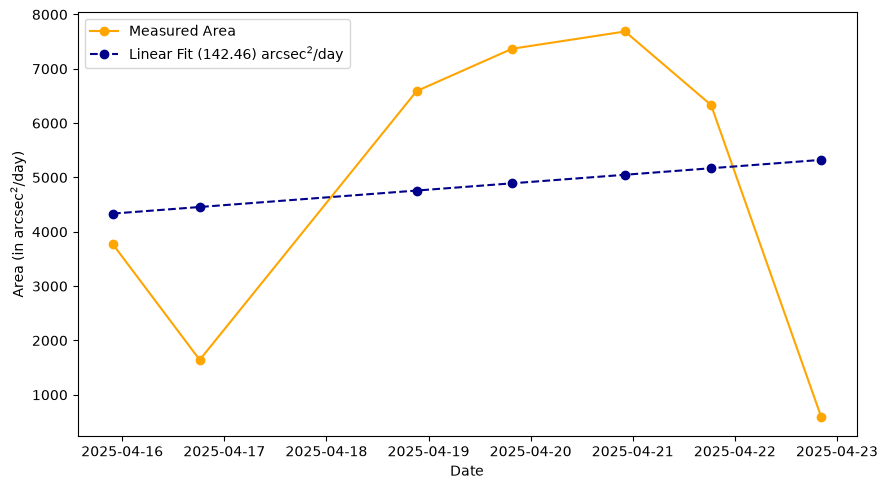

In [8]:
# Plotting the Fit against the Measured Area

plt.figure(figsize=(9, 5))
plt.plot(results["date"], results["area_arcsec^2"], "o-", color="orange", label="Measured Area")
plt.plot(results["date"], fit, "o--", color="darkblue", label=f"Linear Fit ({abs(slope):.2f}) arcsec$^2$/day")
plt.xlabel("Date")
plt.ylabel("Area (in arcsec$^2$/day)")

plt.legend()
plt.tight_layout()
plt.show()

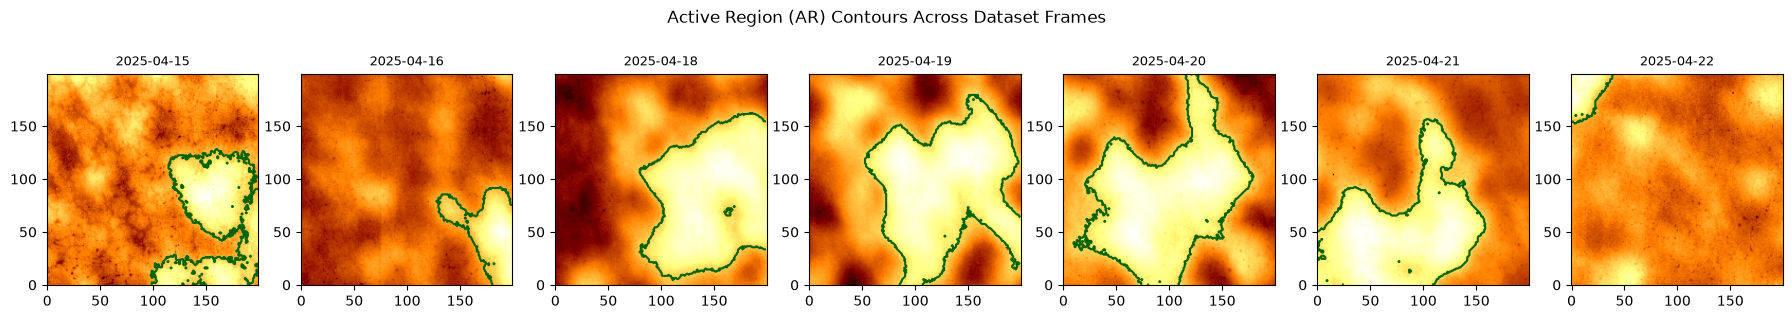

In [20]:
# Highlighting the AR contours across the dataset

dataset_length = len(fits_files_sorted)
fig, axes = plt.subplots(1, dataset_length, figsize=(3.2 * dataset_length, 3.5))

for ax, file, mask, date in zip(axes, fits_files_sorted, region_mask, results["date"]):
    smap_data = Map(file).data
    crop_region = np.nan_to_num(smap_data)[ROW_MIN:ROW_MAX, COL_MIN:COL_MAX]

    ax.imshow(crop_region, cmap="afmhot", origin="lower", norm=ImageNormalize(stretch=SqrtStretch()))
    ax.contour(mask, colors="darkgreen", linewidth=1.5)

    ax.set_title(date.strftime("%Y-%m-%d"), fontsize=9)

plt.suptitle("Active Region (AR) Contours Across Dataset Frames")
plt.show()